# Reliance Chemicals Ltd. – Chemical Reaction Yield Prediction

## Neural Network Regression using a Real Chemical Reaction Dataset

**Project Type:** Machine Learning – Regression  
**Target Variable:** Reaction Yield (%)  
**Dataset:** Suzuki–Miyaura high-throughput reaction dataset

This project predicts experimental chemical reaction yield from recorded reaction-condition variables and demonstrates how neural-network regression can support reaction optimization.


# 1. Problem Statement

Reliance Chemicals Ltd. seeks to optimize chemical production by predicting reaction yields.

Using experimentally recorded reaction conditions, a neural network regression model is developed to estimate chemical reaction yield and support production efficiency.

### Objective
To predict the percentage yield of a chemical reaction.

### Problem Type
Regression

### Input
Reaction-condition variables available in the selected public dataset.

### Output
Reaction Yield (%) – a continuous numerical value.


# 2. Dataset

### Dataset Source
**Public GitHub repository:** `rxn4chemistry/rxn_yields`

### Original Experimental Source
Perera et al., *A platform for automated nanomole-scale reaction screening and micromole-scale synthesis in flow*, **Science, 359(6374), 429–434 (2018)**.

### Dataset Type
Suzuki–Miyaura high-throughput experimental reaction dataset.

### Number of Records
**5,760 experimental reactions**.

### Number of Columns Used
**7 columns**:

1. `Reactant_1_Name`
2. `Reactant_2_Name`
3. `Catalyst_1_Short_Hand`
4. `Ligand_Short_Hand`
5. `Reagent_1_Short_Hand`
6. `Solvent_1_Short_Hand`
7. `Product_Yield_PCT_Area_UV`

### Target Variable
`Product_Yield_PCT_Area_UV`

This is the experimentally measured product yield, expressed as a percentage.

### Important Dataset Note
The problem statement mentions temperature, pressure and reactant concentrations as examples of physicochemical conditions. The selected public Suzuki–Miyaura dataset does **not** contain those measurements. Therefore, this project uses only the reaction-condition variables actually present in the real dataset and does not fabricate missing values.


In [ ]:
# 3. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression

print("Libraries imported successfully.")


In [ ]:
# 4. Load the Real Dataset

DATA_URL = "https://raw.githubusercontent.com/rxn4chemistry/rxn_yields/master/data/Suzuki-Miyaura/aap9112_Data_File_S1.xlsx"

df = pd.read_excel(DATA_URL)

print("Dataset loaded successfully.")
print("Shape of dataset:", df.shape)
print("\nFirst five records:")
display(df.head())


# 4. Data Preprocessing

Data preprocessing is performed to prepare the experimental reaction data for machine-learning regression.

The following steps are carried out:

1. Handling missing values
2. Checking duplicate records
3. Removing irrelevant features
4. Handling outliers
5. Identifying numerical and categorical features
6. Separating features and target
7. Train-test split
8. Encoding and feature scaling


## 4.1 Handling Missing Values

Rows without a measured reaction yield cannot be used as supervised-learning targets. Missing categorical values are handled later using the most-frequent category within the preprocessing pipeline.


In [ ]:
# Check missing values

print("Missing values before cleaning:")
print(df.isnull().sum())


## 4.2 Handling Duplicate Records

Duplicate experimental records are checked and removed if present.


In [ ]:
duplicates = df.duplicated().sum()
print("Number of duplicate records:", duplicates)

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)


## 4.3 Removing Irrelevant Features

Only reaction-condition variables needed for prediction are retained. The measured yield is kept separately as the target variable.


In [ ]:
feature_columns = [
    "Reactant_1_Name",
    "Reactant_2_Name",
    "Catalyst_1_Short_Hand",
    "Ligand_Short_Hand",
    "Reagent_1_Short_Hand",
    "Solvent_1_Short_Hand"
]

target_column = "Product_Yield_PCT_Area_UV"

required_columns = feature_columns + [target_column]
df = df[required_columns].copy()

# Remove rows with missing target and impossible yield values.
df = df.dropna(subset=[target_column])
df = df[(df[target_column] >= 0) & (df[target_column] <= 100)].reset_index(drop=True)

print("Columns retained:", df.columns.tolist())
print("Cleaned dataset shape:", df.shape)


## 4.4 Handling Outliers

Reaction-yield outliers are examined using a boxplot. Extreme experimental results are not automatically deleted because they may represent genuine chemical behavior.


In [ ]:
plt.figure(figsize=(7, 4))
plt.boxplot(df[target_column])
plt.title("Boxplot of Reaction Yield")
plt.ylabel("Reaction Yield (%)")
plt.show()


## 4.5 Identification of Numerical and Categorical Features

The selected reaction-condition variables are categorical. The yield is a numerical target.


In [ ]:
numerical_features = df[feature_columns].select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df[feature_columns].select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)


## 4.6 Separating Features and Target

The independent variables are stored in `X`, while the dependent variable, reaction yield, is stored in `y`.


In [ ]:
X = df[feature_columns].copy()
y = df[target_column].astype(float).copy()

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)


## 4.7 Train-Test Split

The dataset is divided into 80% training data and 20% testing data. The test data remains unseen during model training.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


## 4.8 Encoding and Feature Scaling

The categorical reaction conditions are converted into numerical features using one-hot encoding.

The resulting features are standardized using `StandardScaler`. The preprocessing is fitted only on the training data to avoid data leakage.


In [ ]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Encoded training shape:", X_train_scaled.shape)
print("Encoded testing shape:", X_test_scaled.shape)


# 5. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distribution of reaction yields and the relationship between yield and reaction-condition variables.


In [ ]:
# 5.1 Reaction Yield Distribution

plt.figure(figsize=(8, 5))
plt.hist(df[target_column], bins=30)
plt.title("Distribution of Reaction Yield")
plt.xlabel("Reaction Yield (%)")
plt.ylabel("Frequency")
plt.show()

print(df[target_column].describe())


In [ ]:
# 5.2 Average Yield by Catalyst

catalyst_yield = (
    df.groupby("Catalyst_1_Short_Hand")[target_column]
      .agg(["mean", "count"])
      .sort_values("mean", ascending=False)
)

display(catalyst_yield)

plt.figure(figsize=(10, 5))
catalyst_yield["mean"].plot(kind="bar")
plt.title("Average Reaction Yield by Catalyst")
plt.xlabel("Catalyst")
plt.ylabel("Average Yield (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# 5.3 Average Yield by Ligand

ligand_yield = (
    df.groupby("Ligand_Short_Hand")[target_column]
      .agg(["mean", "count"])
      .sort_values("mean", ascending=False)
)

display(ligand_yield.head(15))

plt.figure(figsize=(10, 5))
ligand_yield["mean"].head(15).plot(kind="bar")
plt.title("Top 15 Ligands by Average Reaction Yield")
plt.xlabel("Ligand")
plt.ylabel("Average Yield (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# 5.4 Average Yield by Solvent

solvent_yield = (
    df.groupby("Solvent_1_Short_Hand")[target_column]
      .agg(["mean", "count"])
      .sort_values("mean", ascending=False)
)

display(solvent_yield)

plt.figure(figsize=(9, 5))
solvent_yield["mean"].plot(kind="bar")
plt.title("Average Reaction Yield by Solvent")
plt.xlabel("Solvent")
plt.ylabel("Average Yield (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 6. Feature Selection

The selected features are the experimentally recorded reaction-condition variables:

- Reactant 1
- Reactant 2
- Catalyst
- Ligand
- Reagent/Base
- Solvent

The reaction yield is the target variable.


In [ ]:
print("Selected input features:")
for feature in feature_columns:
    print("-", feature)

print("\nTarget variable:", target_column)


## 6.1 Feature Relevance Analysis

Because the predictors are categorical rather than continuous, direct Pearson correlation is not appropriate for the raw input columns. Instead, group-wise average yields and the fitted model's feature representation are used to understand which reaction-condition categories contribute useful predictive information.


# 7. Model Building

A neural network regression model is developed because reaction yield is a continuous numerical target.

A simple Linear Regression model and a Dummy Regressor are also included as baselines. The baselines provide context for judging whether the neural network provides useful predictive improvement.


In [ ]:
# 7.1 Prepare model inputs

X_train_nn = X_train_scaled
X_test_nn = X_test_scaled

print("Neural-network input dimensions:", X_train_nn.shape[1])


In [ ]:
# 7.2 Baseline and Neural Network Models

dummy_model = DummyRegressor(strategy="mean")
linear_model = LinearRegression()

neural_network = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.20,
    n_iter_no_change=20,
    random_state=42
)

dummy_model.fit(X_train_nn, y_train)
linear_model.fit(X_train_nn, y_train)
neural_network.fit(X_train_nn, y_train)

print("Dummy, Linear Regression and Neural Network models trained successfully.")


# 8. Model Evaluation

The models are evaluated on the unseen test set using:

1. MAE – Mean Absolute Error
2. MSE – Mean Squared Error
3. RMSE – Root Mean Squared Error
4. R² Score – Coefficient of Determination

For MAE, MSE and RMSE, lower values are better. For R², a value closer to 1 indicates better explanatory performance.


In [ ]:
# 8.1 Generate Predictions

y_pred_dummy = dummy_model.predict(X_test_nn)
y_pred_linear = linear_model.predict(X_test_nn)
y_pred_nn = neural_network.predict(X_test_nn)

print("Predictions generated for all three models.")


In [ ]:
# 8.2 Model Performance Comparison

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Dummy Regressor": regression_metrics(y_test, y_pred_dummy),
    "Linear Regression": regression_metrics(y_test, y_pred_linear),
    "Neural Network": regression_metrics(y_test, y_pred_nn)
}).T

display(results.round(4))

best_model = results["R2"].idxmax()
print("Best model by R²:", best_model)


In [ ]:
# 8.3 Actual vs Predicted Yield – Neural Network

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_nn)

minimum = min(y_test.min(), y_pred_nn.min())
maximum = max(y_test.max(), y_pred_nn.max())

plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.title("Actual vs Predicted Reaction Yield – Neural Network")
plt.xlabel("Actual Reaction Yield (%)")
plt.ylabel("Predicted Reaction Yield (%)")
plt.show()


In [ ]:
# 8.4 Residual Analysis – Neural Network

residuals = y_test - y_pred_nn

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_nn, residuals)
plt.axhline(y=0, linestyle="--")
plt.title("Residual Plot – Neural Network")
plt.xlabel("Predicted Reaction Yield (%)")
plt.ylabel("Residual")
plt.show()

print("Mean residual:", round(float(residuals.mean()), 4))


# 9. Interpretation of Results

## 9.1 Model Performance Summary

The neural network is compared against a simple mean baseline and Linear Regression. The final model should be selected using the regression metrics, with particular attention to R², RMSE and MAE.

## 9.2 Key Findings

The following values are generated directly from the executed test-set predictions:

- Best model by R²
- MAE
- RMSE
- R²
- Highest-average-yield catalyst
- Highest-average-yield solvent
- Highest-average-yield ligand

This avoids making unsupported claims before the notebook is executed.


In [ ]:
# 9.3 Automatically generate the key findings

nn_mae = results.loc["Neural Network", "MAE"]
nn_rmse = results.loc["Neural Network", "RMSE"]
nn_r2 = results.loc["Neural Network", "R2"]

best_catalyst = catalyst_yield["mean"].idxmax()
best_catalyst_yield = catalyst_yield["mean"].max()

best_solvent = solvent_yield["mean"].idxmax()
best_solvent_yield = solvent_yield["mean"].max()

best_ligand = ligand_yield["mean"].idxmax()
best_ligand_yield = ligand_yield["mean"].max()

print("KEY FINDINGS")
print("------------")
print("Best model by R²:", best_model)
print("Neural Network MAE:", round(nn_mae, 4))
print("Neural Network RMSE:", round(nn_rmse, 4))
print("Neural Network R²:", round(nn_r2, 4))
print(
    f"Highest average-yield catalyst: {best_catalyst} "
    f"({best_catalyst_yield:.2f}%)"
)
print(
    f"Highest average-yield solvent: {best_solvent} "
    f"({best_solvent_yield:.2f}%)"
)
print(
    f"Highest average-yield ligand: {best_ligand} "
    f"({best_ligand_yield:.2f}%)"
)


## 9.4 Business Interpretation

The model can support chemical-production decision making by estimating yield from previously observed reaction conditions.

Potential uses include:

- Comparing reaction-condition combinations.
- Identifying categories associated with higher observed yield.
- Reducing unnecessary experimental trials.
- Supporting reaction optimization and planning.

The public dataset is a Suzuki–Miyaura HTE benchmark, not Reliance Chemicals Ltd.'s proprietary production data. Any industrial deployment would require validation on company-specific experiments.


# 10. Flow Diagram

The project workflow is:

**Problem Definition → Real Dataset → Data Understanding → Data Preprocessing → EDA → Feature Selection → Encoding & Scaling → Train-Test Split → Neural Network Regression → Model Training → Model Evaluation → Yield Prediction & Interpretation**


<div style="text-align:center;">
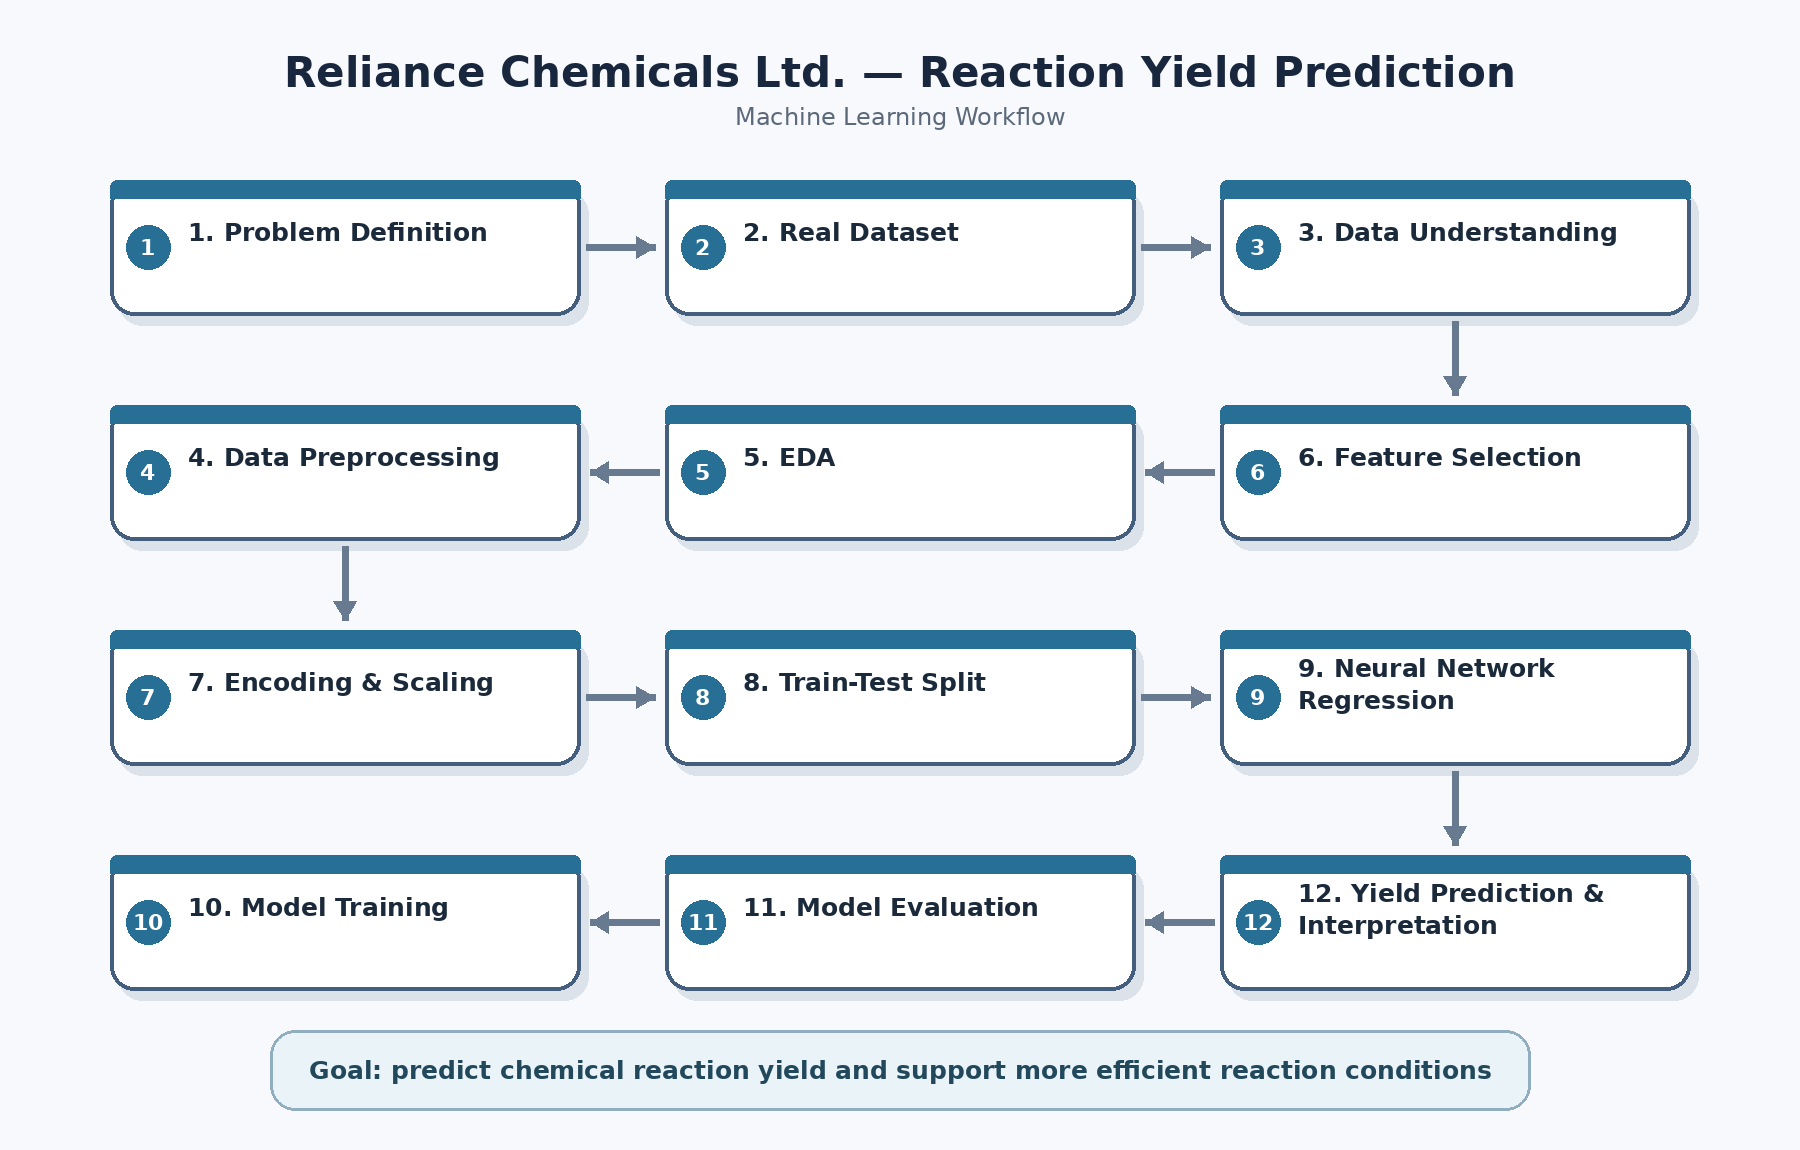
</div>

# Project Conclusion

A neural-network regression workflow was developed for chemical reaction-yield prediction using a real Suzuki–Miyaura high-throughput experimental dataset.

The project follows the structure of the supplied sample while adapting the analysis correctly for regression:

- Dataset documentation
- Data preprocessing
- EDA
- Feature selection
- Train-test split
- Encoding and scaling
- Baseline comparison
- Neural network regression
- MAE, MSE, RMSE and R² evaluation
- Actual-vs-predicted analysis
- Residual analysis
- Key findings
- Business interpretation
- Flow diagram


# Dataset Reference

**Repository:** `rxn4chemistry/rxn_yields`  
**Dataset:** Suzuki–Miyaura reaction dataset  
**File:** `aap9112_Data_File_S1.xlsx`  
**Original publication:** Perera et al., *Science* 359(6374), 429–434 (2018).

The repository documents the Suzuki–Miyaura dataset and shows that its target is derived from `Product_Yield_PCT_Area_UV`. citeturn1view0
